[![Text: CC BY-SA 4.0](https://img.shields.io/badge/text-CC%20BY--SA%204.0-lightgrey.svg)](https://creativecommons.org/licenses/by-sa/4.0/)
[![Code: MIT](https://img.shields.io/badge/code-MIT-yellow.svg)](https://opensource.org/license/mit)

This notebook is part of course materials for CS 545: Machine Learning at
Colorado State University. These notebooks are based on the PyTorch version of
[Dive into Deep Learning](https://d2l.ai) by Aston Zhang, Zachary C. Lipton,
Mu Li and Alexander J. Smola, used under
[CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/) and heavily
modified by [Asa Ben-Hur](https://www.cs.colostate.edu/~asa/) with
[Claude](https://claude.com) AI. The text is released under
[CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/); the code is
released under the [MIT license](https://opensource.org/license/mit).

# From Transformers to Large Language Models

In the previous module we built multi-head attention and assembled the transformer model. Then we met BERT — that same architecture, scaled up and pretrained on billions of words using self-supervised masked-token prediction.  In this module we transition from such encoder models to **decoder-only** models.  Those are trained to do nothing but **predict the next token**.  This is the architecture behind today's large language models.

This notebook is the conceptual map for the construction of such models.  No new architecture will be introduced — the pieces are the ones we already used and built.  What is new is the *objective* (language modeling), the *input representation* (subword tokens), the *scale*, and what falls out of combining the three.  Along the way we will play with a real pretrained model — GPT-2, small enough to run on any laptop — to keep the concepts attached to something that actually works.

Everything here is designed to run on a laptop CPU or Apple-silicon MPS; nothing in this module requires a GPU cluster.

## Three families of pretrained transformers

The original transformer model (Vaswani et al., 2017) was an encoder–decoder architecture designed for machine translation.  Nearly all variants since keep the same transformer building blocks and differ mainly in **which half is kept, and how attention is allowed to flow**.  That single choice sorts pretrained transformers into three families:

* **Encoder-only** (BERT and its descendants).  Every token attends to every other: the model reads its whole input *bidirectionally* and produces one representation per token.  Pretrained by filling in masked tokens.  Built for *understanding* a given text and addresses tasks such as classification, tagging, and retrieval.
* **Encoder–decoder** (the original translation model; T5, BART).  An encoder reads the input; a decoder generates an output sequence token by token, attending *causally* to what it has generated so far and, through cross-attention, to the entire encoded input.  T5's contribution was to cast every task — translation, summarization, even classification — as text in, text out.
* **Decoder-only** (the GPT family — and essentially every model now called an "LLM").  Keep only the decoder stack.  Each token may attend only to tokens before it using the **causal attention** pattern;  the model is trained to predict the next token at every position.

The attention patterns are the real signature of the three families, and they are worth seeing side by side.

In [1]:
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

import numpy as np
import torch
import matplotlib.pyplot as plt

device = ('cuda' if torch.cuda.is_available()
          else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Using {device} device')

Using mps device


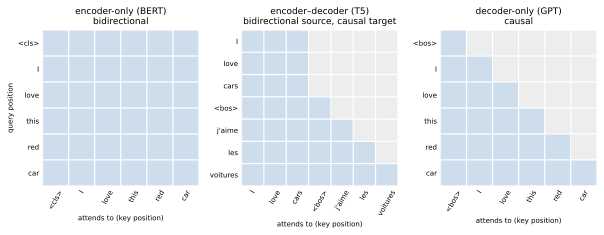

In [2]:
from matplotlib.colors import ListedColormap

BLUE, GREEN, IO = '#cdddec', '#d0e3d4', '#ededed'
AMBER, TX = '#c0662f', '#333333'
allowed = ListedColormap([IO, BLUE])   # 0 = blocked (gray), 1 = allowed (blue)

def show_pattern(ax, mask, toks, title):
    ax.imshow(mask, cmap=allowed, vmin=0, vmax=1)
    ax.set_xticks(range(len(toks)), toks, rotation=60, fontsize=7)
    ax.set_yticks(range(len(toks)), toks, fontsize=7)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('attends to (key position)', fontsize=7)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks(np.arange(-.5, len(toks)), minor=True)
    ax.set_yticks(np.arange(-.5, len(toks)), minor=True)
    ax.grid(which='minor', color='white', linewidth=1.2)
    ax.tick_params(which='both', length=0)

toks = ['<cls>', 'I', 'love', 'this', 'red', 'car']       # encoder input
dec_toks = ['<bos>', 'I', 'love', 'this', 'red', 'car']   # decoder input
src, tgt = ['I', 'love', 'cars'], ['<bos>', "j'aime", 'les', 'voitures']
m, k = len(src), len(tgt)
ed = np.zeros((m + k, m + k))
ed[:m, :m] = 1                          # encoder: source attends to all source
ed[m:, :m] = 1                          # cross-attention: target sees all source
ed[m:, m:] = np.tril(np.ones((k, k)))   # decoder: causal over the target

fig, axes = plt.subplots(1, 3, figsize=(8.5, 3.4))
show_pattern(axes[0], np.ones((len(toks), len(toks))), toks,
             'encoder-only (BERT)\nbidirectional')
show_pattern(axes[1], ed, src + tgt,
             'encoder–decoder (T5)\nbidirectional source, causal target')
show_pattern(axes[2], np.tril(np.ones((len(dec_toks), len(dec_toks)))), dec_toks,
             'decoder-only (GPT)\ncausal')
axes[0].set_ylabel('query position', fontsize=7)
fig.tight_layout();

In the figure above each row is a query position, and the blue cells mark the positions it is allowed to attend to.  The BERT encoder on the left is a full square and represents the pattern of bidirectional attention where every token sees every other.  This is also what makes it unable to generate text.  The encoder–decoder model (center) is a composite: a bidirectional encoder block for the source, a triangle for the target, and a filled rectangle of cross-attention connecting them.  The decoder-only pattern (right) is just the lower triangle: token $t$ sees tokens $1, \dots, t$ and nothing else.

Why has the field converged on the third, seemingly the most restricted architecture?  A few reasons:

* **Simplicity.**  One stack, one attention pattern, one objective.  No input-corruption scheme to design, no special mask tokens, no encoder/decoder split to manage.
* **Dense training signal.**  With a causal mask, *every* position of *every* document is a prediction target, all computed in a single forward pass.  BERT, by contrast, learns only from the ~15% of tokens it masks.
* **It scales.**  The next-token objective improves smoothly and predictably as models, data, and compute grow (see below).

Encoder models are not obsolete — embedding and retrieval models are typically encoder-only to this day.

## Language modeling: predict the next token

A **language model** assigns a probability to a sequence of tokens.  The chain rule of probability factors any such distribution — exactly, with no assumptions — into one conditional per position:

$$P(x_1, x_2, \dots, x_T) \;=\; \prod_{t=1}^{T} P(x_t \mid x_1, \dots, x_{t-1}).$$

An **autoregressive** language model implements the right-hand side directly: a network that, given a prefix, outputs a distribution over what comes next.  Notice what each factor is: a plain **classification problem** — softmax over the vocabulary, one $|V|$-way classifier per position.  We can train such a model with the familiar cross-entropy loss function, averaged over positions:

$$\mathcal{L} = \frac{1}{T}\sum_{t=1}^{T} \underbrace{\left(-\sum_{k=1}^{|V|} \mathbb{1}[k = x_t]\,\log P_{\mathbf{w}}(k \mid x_{<t})\right)}_{\text{cross-entropy at position } t} = -\frac{1}{T}\sum_{t=1}^{T} \log P_{\mathbf{w}}(x_t \mid x_{<t}).$$

Here $P_{\mathbf{w}}(x_t \mid x_{<t})$ is our model, parameterized by its parameters $\mathbf{w}$, and $x_{<t}$ refers to all the tokens before time step $t$.

Machinery-wise, nothing here is new to us; what is new is where the labels come from.  Like BERT's masked-word objective, this is **self-supervised** — the "label" at each position is simply the next token of the text itself, so every book, webpage, and source file is free training data.  But it is even simpler than BERT's scheme: **no masking is performed**, simply the text shifted by one.

**Implementation.**  Feed the model `<bos>`$, x_1, \dots, x_{T-1}$ and ask it, at every position simultaneously, to predict $x_1, \dots, x_T$.  We add a **causal mask** into the attention computation that prevents the model from looking ahead.  In this setup a token can only attend to tokens that came before it.

The quantity $\exp(\mathcal{L})$ has a name — **perplexity**.  It is one of the evaluation metrics for LLMs, and is introduced in the next notebook.  And this loss, computed over a causally-masked stack of the blocks we built in the attention module, is the entire pretraining recipe of the GPT family of LLMs.  It will be implemented from scratch in notebook 3.

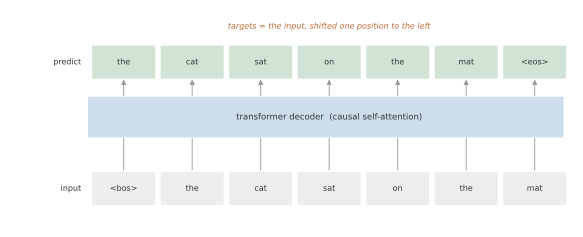

In [3]:
from matplotlib.patches import FancyBboxPatch

inp = ['<bos>', 'the', 'cat', 'sat', 'on', 'the', 'mat']
tgt = ['the', 'cat', 'sat', 'on', 'the', 'mat', '<eos>']

fig, ax = plt.subplots(figsize=(8.2, 3.4))
BW = 0.88
for i, t in enumerate(inp):
    ax.add_patch(FancyBboxPatch((i - BW/2, -0.28), BW, 0.56,
                 boxstyle='round,pad=0.02', facecolor=IO, edgecolor='none'))
    ax.text(i, 0, t, ha='center', va='center', fontsize=8, color=TX)
ax.add_patch(FancyBboxPatch((-0.5, 0.95), len(inp) - 0.1, 0.7,
             boxstyle='round,pad=0.02', facecolor=BLUE, edgecolor='none'))
ax.text((len(inp) - 1) / 2, 1.3,
        'transformer decoder  (causal self-attention)',
        ha='center', va='center', fontsize=8.5, color=TX)
for i in range(len(inp)):
    ax.annotate('', xy=(i, 0.95), xytext=(i, 0.30),
                arrowprops=dict(arrowstyle='-', color='0.6', lw=0.9))
    ax.annotate('', xy=(i, 2.02), xytext=(i, 1.65),
                arrowprops=dict(arrowstyle='-|>', color='0.6', lw=0.9))
for i, t in enumerate(tgt):
    ax.add_patch(FancyBboxPatch((i - BW/2, 2.02), BW, 0.56,
                 boxstyle='round,pad=0.02', facecolor=GREEN, edgecolor='none'))
    ax.text(i, 2.3, t, ha='center', va='center', fontsize=8, color=TX)
ax.text((len(inp) - 1) / 2, 2.95,
        'targets = the input, shifted one position to the left',
        ha='center', va='center', fontsize=8, style='italic', color=AMBER)
ax.text(-0.62, 0, 'input', ha='right', va='center', fontsize=8, color=TX)
ax.text(-0.62, 2.3, 'predict', ha='right', va='center', fontsize=8, color=TX)
ax.set_xlim(-1.7, len(inp) - 0.4)
ax.set_ylim(-0.75, 3.3)
ax.axis('off')
plt.tight_layout();

The output at position $t$ is a full distribution over the vocabulary, computed — thanks to the causal mask — from the prefix `<bos>`$, x_1, \dots, x_{t-1}$.  Each column of the figure is therefore a self-contained instance of the same problem: *given this prefix, what comes next?*  Our one sentence poses that problem seven times — $P(\text{the} \mid \texttt{<bos>})$, then $P(\text{cat} \mid \texttt{<bos>}\,\text{the})$, all the way to $P(\texttt{<eos>} \mid \texttt{<bos>}\,\text{the cat sat on the mat})$.  The "shift" is not an operation the model performs, and not something it must learn; it only describes where the loss finds each column's correct answer — the label for the prefix ending at position $t$ happens to be stored at position $t+1$ of the same tensor.  The model learns one thing, the conditional distribution $P_{\mathbf{w}}(x_t \mid x_{<t})$, and training simply evaluates it at all $T$ prefixes of the sequence in a single forward pass.  That is the "dense training signal" mentioned earlier: one sentence, $T$ gradient-carrying predictions.
At *generation* time, by contrast, only the last prediction is used.

There is a real difference between this model and BERT which decides how you build a classifier on either.  To predict $x_{t+1}$ well, the representation at position $t$ must encode whatever about $x_1, \dots, x_t$ bears on what comes next.  That is a weaker demand than "summarize everything" since much of what predicts the next token is local.  But it is applied at *every* position of *every* training document, and satisfying it for a hard enough continuation requires carrying a great deal forward.  Every position is therefore under gradient pressure to become a running summary of its own prefix, and the last position, whose prefix is the whole sequence, is the closest thing the model has to a summary of everything it has read.

BERT's `<cls>` slot receives no comparable signal.  Masked language modeling never asks `<cls>` to predict anything; it earns gradient only insofar as *other* positions find it useful to attend to, and since its input embedding is the same for every input it starts with nothing of its own to offer.  Whatever summary it ends up holding is installed later, by fine-tuning on a task that reads from it.  This is why a causal model needs no designated summary token — its final position already is one (see exercise 1).

## GPT-2

Before training an LLM, let us use one that has already been trained and inspect what it provides: the conditional distribution $P_{\mathbf{w}}(x_t \mid x_{<t})$.

**GPT-2** (Radford et al., 2019) is the natural choice: a decoder-only transformer trained on 40 GB of web text, state of the art in 2019, the direct ancestor of every model with "GPT" in its name — and its smallest version, at 124M parameters, runs comfortably on a laptop.  As with DistilBERT in the previous module, the first call downloads the weights (~550 MB) and caches them; later calls are instant.

In [4]:
from transformers import AutoTokenizer, AutoModelForCausalLM

LM_NAME = 'gpt2'   # the 124M-parameter "small" — GPT-2 came in 4 sizes up to 1.5B
tok = AutoTokenizer.from_pretrained(LM_NAME)
lm = AutoModelForCausalLM.from_pretrained(LM_NAME).to(device).eval()

n_params = sum(p.numel() for p in lm.parameters())
print(f'{n_params / 1e6:.0f}M parameters, vocabulary of {len(tok)} tokens')

124M parameters, vocabulary of 50257 tokens


In [5]:
@torch.no_grad()
def next_token_probs(prompt, top_k=5):
    """Print the model's top-k candidates for the single next token."""
    ids = tok(prompt, return_tensors='pt').to(device)
    logits = lm(**ids).logits[0, -1]      # one score for every vocabulary token
    probs = logits.softmax(-1)
    top = probs.topk(top_k)
    print(f'{prompt!r}')
    for p, i in zip(top.values, top.indices):
        print(f'    {tok.decode(i)!r:16s} {p.item():.3f}')
    print()

for prompt in ['The capital of France is',
               'I sat down on the river bank and watched the',
               'import numpy as',
               'The opposite of hot is']:
    next_token_probs(prompt)

'The capital of France is'
    ' the'           0.085
    ' now'           0.048
    ' a'             0.046
    ' France'        0.032
    ' Paris'         0.032

'I sat down on the river bank and watched the'
    ' river'         0.037
    ' water'         0.026
    ' sun'           0.021
    ' sky'           0.015
    ' stream'        0.009

'import numpy as'
    ' np'            0.849
    ' n'             0.037
    ' p'             0.016
    ' f'             0.012
    ' u'             0.007

'The opposite of hot is'
    ' cold'          0.163
    ' the'           0.082
    ' a'             0.062
    ' hot'           0.040
    ' not'           0.038



Look at where the probability goes: word-sense disambiguation (*river* bank pulls the continuation toward water, not money — the contextualization we measured layer by layer in the BERT notebook), Python idiom (`np`), lexical relations (*cold*).  It all condensed out of one objective — predict the next token — applied to a lot of text.  *Paris* only comes fifth, at 3%, behind ' the', ' now' and ' a'; for a less famous fact such as `'The capital of Colorado is'`, *Denver* may not make the top five at all.  Factual recall at this scale is among the things that improve most dramatically with scale; keep this experiment in mind when we explore larger, better-trained models in notebook 4.  The distribution *is* the model: everything it "knows" is visible only as an arrangement of probability mass over continuations.

This should feel like BERT's `fill-mask` demo, with one crucial difference: the prediction uses only the *left* context.  And that difference is important, because a model that predicts what comes next can **write**.  Feed it a prompt, pick a token from its distribution, append that token to the prompt, and repeat:

In [6]:
@torch.no_grad()
def generate_greedy(prompt, n_tokens=40):
    """The autoregressive loop, in its simplest (greedy) form."""
    ids = tok(prompt, return_tensors='pt')['input_ids'].to(device)
    for _ in range(n_tokens):
        logits = lm(ids).logits[0, -1]        # distribution over the next token
        next_id = logits.argmax()             # greedy: always take the top one
        ids = torch.cat([ids, next_id.view(1, 1)], dim=1)
    return tok.decode(ids[0])

print(generate_greedy('In deep learning, the transformer architecture'))

In deep learning, the transformer architecture is a simple way to create a new type of data structure.

The transformer architecture is a simple way to create a new type of data structure. The transformer architecture is a simple way to create


Notice that within 40 tokens it is already repeating itself, a characteristic failure of always taking the single most likely token.  The fix is to *sample* from the distribution instead, and how exactly to sample is explored in a later notebook.

This loop is the core of text generation, and it is why generation is priced per token and why long answers take longer than short ones. Production systems build a lot around it. A KV cache stores the attention keys and values of earlier tokens, so each step processes only the new one. Speculative decoding has a small draft model propose several tokens, which the large model then checks in a single forward pass. Reasoning models generate a long chain of thought before answering, spending more computation on harder questions. Assistants interleave generation with tool calls, such as search or code execution, and feed the results back into the context. Some systems sample several candidate answers and pick the best. Underneath all of this, each token is still chosen from the distribution encoded by the model.

## Tokens: the model's alphabet

We have been using the term "token" without ever defining it.  Time to look at this more carefully, because the choice of tokenization is consequential.

The two obvious options both have serious problems.  **Words**, which we used in the RNN and transformer modules, give short sequences but an unbounded vocabulary: any word not in it becomes `<unk>` (recall how rare words starved for gradient in the IMDb models), and morphology is wasted — *slow*, *slower*, *slowest* are treated as unrelated.  **Characters** solve coverage with a tiny alphabet, but sequences get several times longer — painful when self-attention costs $O(T^2)$ — and each position carries almost no meaning on its own.

**Subword tokenization** is the compromise every modern LLM uses, and **byte-pair encoding** (BPE; Sennrich et al., 2016, adapting a 1994 compression algorithm) is its standard construction.  The algorithm is almost embarrassingly simple:

1. Start with a base alphabet (characters, or raw bytes) and split the corpus into it.
2. Count all adjacent symbol pairs; **merge** the most frequent pair into a new symbol.
3. Repeat step 2 for a fixed number of merges.  The vocabulary is the base alphabet plus every merged symbol.

Frequent words end up as single tokens; rare words decompose into meaningful pieces; and *nothing* is ever out-of-vocabulary.  The algorithm fits in a screenful of code, so let us run it on a toy corpus and watch what it discovers:

In [7]:
from collections import Counter

corpus = 'low lower lowest new newer newest wide wider widest slow slower slowest'
# each word starts as a sequence of characters, plus an end-of-word marker
words = Counter(tuple(w) + ('_',) for w in corpus.split())

def most_frequent_pair(words):
    pairs = Counter()
    for w, c in words.items():
        for pair in zip(w, w[1:]):
            pairs[pair] += c
    return max(pairs, key=pairs.get)

def apply_merge(words, pair):
    a, b = pair
    out = {}
    for w, c in words.items():
        new, i = [], 0
        while i < len(w):
            if i + 1 < len(w) and (w[i], w[i + 1]) == pair:
                new.append(a + b)
                i += 2
            else:
                new.append(w[i])
                i += 1
        out[tuple(new)] = c
    return out

for step in range(1, 11):
    pair = most_frequent_pair(words)
    words = apply_merge(words, pair)
    print(f'merge {step:2d}: {pair[0]!r} + {pair[1]!r}  ->  {pair[0] + pair[1]!r}')

print('\nresulting segmentations:')
for w in sorted(words, key=lambda w: ''.join(w)):
    print('   ', ' | '.join(w))

merge  1: 'l' + 'o'  ->  'lo'
merge  2: 'lo' + 'w'  ->  'low'
merge  3: 'low' + 'e'  ->  'lowe'
merge  4: 'r' + '_'  ->  'r_'
merge  5: 's' + 't'  ->  'st'
merge  6: 'st' + '_'  ->  'st_'
merge  7: 'n' + 'e'  ->  'ne'
merge  8: 'ne' + 'w'  ->  'new'
merge  9: 'w' + 'i'  ->  'wi'
merge 10: 'wi' + 'd'  ->  'wid'

resulting segmentations:
    low | _
    lowe | r_
    lowe | st_
    new | _
    new | e | r_
    new | e | st_
    s | low | _
    s | lowe | r_
    s | lowe | st_
    wid | e | _
    wid | e | r_
    wid | e | st_


The resulting list of tokens is a mix of stems and suffix fragments — pieces like `low` and the endings that build *-er* and *-est* forms, discovered purely by counting, with no notion of morphology built in.  A real tokenizer is built over gigabytes of text, starting from raw *bytes* so that any UTF-8 string can be tokenized.  GPT-2's tokenizer has 50,257 tokens (50,000 merges, 256 byte symbols, and one end-of-text marker).  This is exactly the size of the word distribution in the demos above.

Here is how it carves up real text (in the printout, `Ġ` marks a token that *begins with a space* — the space is part of the token):

In [8]:
def show_tokens(text):
    pieces = tok.tokenize(text)
    print(f'{len(pieces):3d} tokens |', ' '.join(pieces))

show_tokens('The quick brown fox jumps over the lazy dog.')
show_tokens('Transformers are surprisingly effective.')
show_tokens('Antidisestablishmentarianism!')
show_tokens('strawberry Strawberry STRAWBERRY')
show_tokens('pi = 3.14159265358979')
show_tokens('El zorro marrón salta sobre el perro perezoso.')

print()
print("'hello'  ->", tok('hello')['input_ids'],
      "   ' hello' ->", tok(' hello')['input_ids'],
      "   'Hello' ->", tok('Hello')['input_ids'])

 10 tokens | The Ġquick Ġbrown Ġfox Ġjumps Ġover Ġthe Ġlazy Ġdog .
  6 tokens | Transform ers Ġare Ġsurprisingly Ġeffective .
  6 tokens | Ant idis establishment arian ism !
  8 tokens | st raw berry ĠStrawberry ĠST RAW BER RY
 10 tokens | pi Ġ= Ġ3 . 14 159 265 35 89 79
 19 tokens | El Ġz or ro Ġmar r Ã³n Ġsalt a Ġso bre Ġel Ġper ro Ġp ere z oso .

'hello'  -> [31373]    ' hello' -> [23748]    'Hello' -> [15496]


What did we learn from this:

* **Common English words are single tokens; rare words are broken.**  *Antidisestablishmentarianism* becomes a string of fragments — the model must reassemble its meaning from pieces, as we hoped BPE would allow.
* **Case and leading/trailing spaces change the tokens.**  `hello`, ` hello`, and `Hello` are represented by three different tokens; *strawberry* is tokenized differently in each casing.  Early models like GPT-2 can be oddly sensitive to such details, and prompt formatting (e.g. a stray trailing space) are a real failure mode (see below).
* **The model never sees letters.**  If *strawberry* reaches the model as two or three opaque fragments, counting the r's in it requires knowledge the input representation actively hides.  The famous failures of LLMs at letter-counting and spelling games are a result of tokenization.
* **Digits are chopped by frequency.** GPT-2 merges digit strings like any other text, so $\phi$ becomes `3 . 14 159 265 35 89 79`, and multi-digit arithmetic must be learned over inconsistent chunks. Newer tokenizers split numbers by a fixed rule: single digits (Llama 1–2) or chunks of up to three (GPT-4, Llama 3).
* **Non-English text costs more.**  The Spanish sentence needs far more tokens than its English counterpart (`Ã³` is how GPT-2's byte-level tokenizer displays the two UTF-8 bytes of *ó*), because GPT-2's merges were learned mostly on English.  More tokens per sentence means higher cost, slower generation, and less effective context for other languages.
* **Token counts are tokenizer-relative.**  A "per-token" quantity — cost, context length, or a per-token loss — means nothing across models with different tokenizers.

The following demonstrates the sensitivity to trailing spaces:

In [11]:
next_token_probs('The capital of France is')
next_token_probs('The capital of France is ')

'The capital of France is'
    ' the'           0.085
    ' now'           0.048
    ' a'             0.046
    ' France'        0.032
    ' Paris'         0.032

'The capital of France is '
    '\xa0'           0.398
    'ét'             0.342
    'Â'              0.091
    'vern'           0.068
    'iced'           0.012



## GPT to GPT-3, and the scaling laws that drive model growth

The framework for modern LLMs was in place by 2018–2019.  One of the factors that turned this recipe into the success of modern LLMs is the discovery of how far and how predictably they improve with scale.

The **GPT** lineage of models tells the story.  GPT (Radford et al., 2018; 117M parameters) showed that a decoder pretrained on next-token prediction, then *fine-tuned* per task BERT-style, beat task-specific architectures.  **GPT-2** (2019; up to 1.5B) showed something stranger: pretrained on 40 GB of web text, it could perform translation, summarization, and question answering *without any fine-tuning*, just by being prompted — a hint that one generalist might replace the one-model-per-task workflow.  **GPT-3** (Brown et al., 2020; 175B, trained on ~300B tokens) turned that into the paradigm of chat-based models we are so familiar with nowadays.

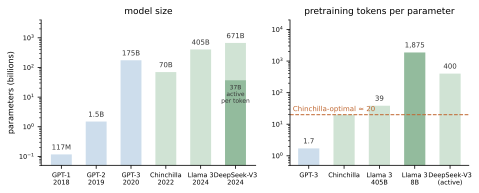

In [13]:
def scaling_figure():
    """Model size and pretraining tokens per parameter, on log scales."""
    ACTIVE = '#93bb9d'   # darker green: parameters active per token (MoE)

    # left panel: name, year, total parameters (B), active parameters (B)
    sizes = [
        ('GPT-1',        2018,   0.117,   0.117),
        ('GPT-2',        2019,   1.5,     1.5),
        ('GPT-3',        2020, 175,     175),
        ('Chinchilla',   2022,  70,      70),
        ('Llama 3',      2024, 405,     405),
        ('DeepSeek-V3',  2024, 671,      37),
    ]
    # right panel: name, pretraining tokens (B), parameters used in the ratio (B)
    data = [
        ('GPT-3',          300, 175),
        ('Chinchilla',    1400,  70),
        ('Llama 3\n405B', 15600, 405),
        ('Llama 3\n8B',   15000,   8),
        ('DeepSeek-V3\n(active)', 14800, 37),
    ]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.8, 2.8),
                                   gridspec_kw={'width_ratios': [6, 5]})

    # left: model size; for the MoE model, the active part is drawn on top
    labels = [f'{name}\n{year}' for name, year, _, _ in sizes]
    totals = [total for _, _, total, _ in sizes]
    actives = [active for _, _, _, active in sizes]
    colors = [BLUE if name.startswith('GPT') else GREEN
              for name, _, _, _ in sizes]
    ax1.bar(labels, totals, color=colors, width=0.6)
    moe = len(sizes) - 1
    ax1.bar(moe, actives[moe], color=ACTIVE, width=0.6)
    ax1.text(moe, actives[moe] / 3, f'{actives[moe]:g}B\nactive\nper token',
             ha='center', va='center', fontsize=6, color=TX)
    for i, total in enumerate(totals):
        text = f'{total * 1000:.0f}M' if total < 1 else f'{total:g}B'
        ax1.text(i, total * 1.3, text, ha='center', va='bottom',
                 fontsize=7, color=TX)
    ax1.set_yscale('log')
    ax1.set_ylim(0.05, 4000)
    ax1.set_ylabel('parameters (billions)', fontsize=8)
    ax1.set_title('model size', fontsize=9)

    # right: pretraining tokens per parameter
    names = [name for name, _, _ in data]
    ratios = [tokens / params for _, tokens, params in data]
    colors = [BLUE, GREEN, GREEN, ACTIVE, GREEN]
    ax2.bar(names, ratios, color=colors, width=0.6)
    ax2.axhline(20, color=AMBER, linestyle='--', linewidth=1)
    ax2.text(-0.45, 26, 'Chinchilla-optimal ≈ 20', fontsize=7, color=AMBER)
    for i, ratio in enumerate(ratios):
        if names[i] == 'Chinchilla':   # its value is the dashed line
            continue
        text = f'{ratio:.1f}' if ratio < 10 else f'{ratio:,.0f}'
        ax2.text(i, ratio * 1.3, text, ha='center', va='bottom',
                 fontsize=7, color=TX)
    ax2.set_yscale('log')
    ax2.set_ylim(0.5, 20000)
    ax2.set_title('pretraining tokens per parameter', fontsize=9)

    for ax in (ax1, ax2):
        ax.tick_params(labelsize=6.5)
        for side in ('top', 'right'):
            ax.spines[side].set_visible(False)
    fig.tight_layout()


scaling_figure()

What justified betting ever-larger compute budgets on one simple objective was an empirical regularity (Kaplan et al., 2020): language-modeling loss falls as a **power law** in model size, dataset size, and training compute, over many orders of magnitude:

![Transformer language-model performance improves smoothly as model size, dataset size, and training compute increase, following a power law in each factor when not bottlenecked by the other two (figure from Kaplan et al., 2020).](https://github.com/d2l-ai/d2l-en/raw/refs/heads/master/img/scaling-power-law.png)

This converts "scale it up" from a gamble into something close to an engineering projection: you can *forecast* the loss of a model before spending the compute to train it.

The scaling story has a second continued with **Chinchilla** (Hoffmann et al., 2022).  That paper showed that the first-generation giants had the balance wrong: for a fixed compute budget, parameters and training tokens should grow together, roughly 20 tokens per parameter, and a 70B model trained on 1.4T tokens beat much larger models trained on less data.  Modern practice has moved past even that: today's small open models (the 0.5–1B ones we will run in notebook 4) are trained on *trillions* of tokens, far beyond their "compute-optimal" share.

Scaling laws, Chinchilla’s included, describe pretraining loss. Lower loss tends to bring better downstream performance, but the abilities of current models also depend on data quality, on post-training (discussed below), and on how much computation the model spends at inference time, for example on a long chain of reasoning, which has scaling behavior of its own.

## In-context learning

Scale did not just lower the loss; it changed how the models are *used*.  GPT-3's headline result was **in-context learning**: describe a task in the prompt — optionally with a few worked input–output examples — and the model performs it on the next input, *with no parameter updates at all*.

The following illustration is the one from the GPT-3 paper: translating an English word into French, with the task specified, and optionally demonstrated, entirely in the prompt.

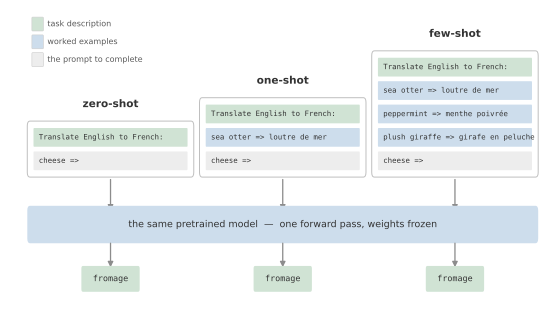

In [9]:
# zero-, one- and few-shot prompting, after Brown et al. (2020), figure 2.1
from matplotlib.patches import FancyArrowPatch

def in_context_learning_figure():
    """Zero-, one- and few-shot prompting: the same frozen model, three prompts."""
    TASK = 'Translate English to French:'
    EXAMPLES = ['sea otter => loutre de mer',
                'peppermint => menthe poivrée',
                'plush giraffe => girafe en peluche']
    PROMPT = 'cheese =>'

    panels = [('zero-shot', 0), ('one-shot', 1), ('few-shot', 3)]
    LH, W, CX = 1.25, 14.0, [8.0, 23.0, 38.0]      # line height, box width, centres
    Y_BAR, Y_OUT = -3.4, -6.3

    fig, ax = plt.subplots(figsize=(8, 4.5))

    def mono(x, y, s, color=TX, ha='left', size=7.4, weight='normal'):
        ax.text(x, y, s, family='monospace', fontsize=size, color=color,
                ha=ha, va='center', weight=weight)

    for (name, n_ex), cx in zip(panels, CX):
        rows = [(TASK, GREEN)] + [(e, BLUE) for e in EXAMPLES[:n_ex]] \
               + [(PROMPT, IO)]
        left = cx - W / 2
        top = (len(rows) - 1) * LH
        # the prompt as one block, with each line tinted by its role
        ax.add_patch(FancyBboxPatch((left, -0.62), W, top + 1.24,
                                    boxstyle='round,pad=0.25', facecolor='white',
                                    edgecolor='0.75', linewidth=1.0))
        for k, (text, fc) in enumerate(rows):
            y = top - k * LH
            ax.add_patch(FancyBboxPatch((left + 0.35, y - 0.44), W - 0.7, 0.88,
                                        boxstyle='round,pad=0.06', facecolor=fc,
                                        edgecolor='none'))
            mono(left + 0.75, y, text)
        ax.text(cx, top + 1.5, name, ha='center', va='bottom', fontsize=10.5,
                color=TX, fontweight='bold')
        ax.add_patch(FancyArrowPatch((cx, -1.0), (cx, Y_BAR + 0.75),
                                     arrowstyle='-|>', mutation_scale=11,
                                     color='0.55', linewidth=1.3, shrinkA=0,
                                     shrinkB=0))

    # one model, three prompts
    ax.add_patch(FancyBboxPatch((CX[0] - W / 2, Y_BAR - 0.75),
                                CX[2] - CX[0] + W, 1.5,
                                boxstyle='round,pad=0.25', facecolor=BLUE,
                                edgecolor='none'))
    ax.text((CX[0] + CX[2]) / 2, Y_BAR,
            'the same pretrained model  —  one forward pass, weights frozen',
            ha='center', va='center', fontsize=9.5, color=TX)

    for cx in CX:
        ax.add_patch(FancyArrowPatch((cx, Y_BAR - 1.0), (cx, Y_OUT + 0.62),
                                     arrowstyle='-|>', mutation_scale=11,
                                     color='0.55', linewidth=1.3, shrinkA=0,
                                     shrinkB=0))
        ax.add_patch(FancyBboxPatch((cx - 2.4, Y_OUT - 0.55), 4.8, 1.1,
                                    boxstyle='round,pad=0.14', facecolor=GREEN,
                                    edgecolor='none'))
        mono(cx, Y_OUT, 'fromage', ha='center', size=8.4)

    # what the three colours mean
    key = [(GREEN, 'task description'), (BLUE, 'worked examples'),
           (IO, 'the prompt to complete')]
    for k, (fc, label) in enumerate(key):
        y = 7.3 - k * 0.95
        ax.add_patch(FancyBboxPatch((1.2, y - 0.32), 0.9, 0.64,
                                    boxstyle='round,pad=0.05', facecolor=fc,
                                    edgecolor='0.8', linewidth=0.6))
        ax.text(2.5, y, label, fontsize=8, va='center', color='0.35')

    ax.set_xlim(-1.0, 46.0)
    ax.set_ylim(Y_OUT - 1.6, 8.2)
    ax.axis('off')
    fig.tight_layout()


in_context_learning_figure()

The terminology: **zero-shot** (task description only), **one-shot** (one example), **few-shot** (a handful).  Everywhere else in this course, "learning" has meant gradient descent on parameters.  Here the parameters are frozen; the "learning" happens inside a single forward pass, conditioned on the prompt — because predicting the continuation of a document that contains worked examples *requires* inferring the pattern connecting them.

In-context learning is why **prompting** became a practical engineering discipline: the prompt is the program.  One technique deserves special mention: **chain-of-thought** prompting (Wei et al., 2022) — showing or simply asking for intermediate reasoning steps before the answer ("let's think step by step") — substantially improves performance on math and multi-step reasoning.  Its descendants are the *reasoning models* of the last two years, trained to produce long internal chains of thought before answering.

## From next-token predictor to assistant

One gap remains between the discussion above and the chatbots we currently use.  A pretrained language model is an *autocomplete*, not an assistant.  Ask a **base model** "What is the capital of Colorado?" and it may well continue with *nine more quiz questions* — because a list of questions is a perfectly likely document.  It gives the most probable continuation, not the most helpful response.  (You can try this: put a question to `generate_greedy` above and watch what GPT-2 does with it.)

Turning a next token prediction model into an assistant is **post-training**, and the modern pipeline has three stages:

1. **Pretraining**: Next-token prediction on trillions of tokens.  Nearly all of the compute, and the source of essentially all of the model's capability.
2. **Instruction tuning (supervised fine-tuning, SFT)**: continue training, with the *same* next-token objective, on a curated corpus of (instruction, response) pairs.  The data reshapes behavior from "continue the document" to "answer the request" (Wei et al., 2021; Sanh et al., 2021).
3. **Preference tuning**: collect human (or AI) judgments comparing candidate responses, and optimize the model toward preferred ones: **RLHF**, reinforcement learning from human feedback (Ouyang et al., 2022 — the InstructGPT recipe that created ChatGPT), or simpler direct methods such as **DPO** (Rafailov et al., 2023).  Preference tuning shapes helpfulness, format, and when the model declines a request; deployed chatbots usually add separate safety classifiers on inputs and outputs as well.

Open-weight model families (Llama, Qwen, Gemma, Mistral, and the rest) typically publish both the **base** and the **instruct** checkpoints of the same model.  That pair is a perfect controlled experiment:  the same architecture and pretraining, differing post-training — and comparing their answers to identical prompts, in notebook 4, is the clearest demonstration of what post-training does.  In notebook 5 we will perform a small instruction-tuning run ourselves, with LoRA.

One closing comment.  The models we will load in notebook 4 are, architecturally, the decoder-only transformer of this notebook with incremental refinements — rotary position embeddings instead of sinusoids, RMSNorm instead of LayerNorm, grouped-query attention to shrink the KV cache — every one of them a variation on a component we have already built.  Nothing ahead is architecturally different.

### What's next

* **Notebook 2** makes the language-modeling objective quantitative: cross-entropy and **perplexity**, measured on real models.
* **Notebook 3** trains a GPT **from scratch** — a small one, on a corpus chosen so that a small model can visibly succeed.
* **Notebook 4** works with modern pretrained LLMs on your laptop: sampling strategies, prompting and in-context learning, and what instruction tuning changes.
* **Notebook 5** adapts a pretrained model to new behavior with parameter-efficient (**LoRA**) fine-tuning.

## Summary

* Pretrained transformers come in three families distinguished by their **attention pattern**: encoder-only (bidirectional; BERT, previous module), encoder–decoder (T5), and **decoder-only** (causal; GPT) — the LLM architecture, and this module's focus.
* **Language modeling** is next-token prediction: the chain rule factors any sequence distribution into per-position conditionals, each a $|V|$-way classification trained with cross-entropy.  Self-supervised, so all text is training data; the causal mask plus shifted targets make every position a training example in one parallel forward pass.  $\exp(\text{loss})$ is **perplexity** (notebook 2).
* **Generation** is the autoregressive loop: forward pass, pick a token, append, repeat.  Greedy picking degenerates into repetition; principled sampling is notebook 4's topic.
* **BPE tokenization** builds a subword vocabulary by iteratively merging frequent pairs: no out-of-vocabulary words, but real artifacts — case/whitespace sensitivity, hidden letters, chopped digits, higher token costs for non-English text.
* **Scaling laws** make loss a predictable power law in model size, data, and compute; Chinchilla set the parameter–token balance, and modern small models deliberately train far past it.  At scale, **in-context learning** emerges: tasks specified in the prompt, no weight updates.
* A base model autocompletes; **post-training** (instruction tuning + preference tuning) makes it an assistant.  Base-vs-instruct pairs of open models let us see exactly what that changes.

## Exercises

1. **Classification with a decoder.**  Suppose you must build a sentiment classifier from a pretrained *decoder-only* model by attaching a linear head, as we did with BERT.  BERT used the `<cls>` token — at the *front*.  Why is the front token a bad readout point for a causal model, and which position should you use instead?  Give a second, training-free alternative: how could you pose sentiment classification as a next-token prediction problem (what prompt, and which tokens' probabilities would you compare)?

2. **Decoder-only translation.**  For sequence-to-sequence tasks such as translation, the encoder–decoder lets every target token see the *entire* source bidirectionally.  What does a decoder-only model give up when the source is simply placed in the prompt?  Why does this matter less at large scale than the architecture diagram suggests?

3. **Tokenizers.**  Using `show_tokens`, find (a) the shortest common English word that GPT-2 splits into three or more pieces, and (b) a pair of words with closely related meanings that share *no* tokens.  Then compare token counts for the same paragraph in English and another language of your choice.  What are the practical consequences for cost, effective context length, and multilingual users?

4. **Probing the distribution.**  Design prompts for `next_token_probs` that test (a) factual recall, (b) grammatical agreement across a long dependency ("The keys to the cabinet ___"), and (c) genuine ambiguity, where the distribution *should* be spread out.  When is a confidently peaked distribution a good sign, and when is it a failure?

5. **Greedy degeneration.**  Raise `n_tokens` in `generate_greedy` to 150 and find a prompt that drives the model into a repetition loop.  Why does always taking the argmax cause loops that sampling would escape?  (Think about what happens once a phrase has appeared twice.)

6. **Why BERT cannot chat.**  Explain, in terms of the attention patterns in the first figure, why BERT has no natural way to generate text left to right — and why a causal model can be trained on *all* positions of a document at once while BERT can only learn from its masked positions.  Both facts follow from the same design choice.